# Project Overview

This project explores patterns in employee attrition using the IBM HR Analytics Employee Attrition & Performance dataset. Using Python, pandas, and matplotlib, I analyze how attrition varies across departments, overtime status, and job satisfaction levels.

The goal is to identify workforce trends and demonstrate how data analysis can support HR decision-making.

Dataset: IBM HR Analytics Employee Attrition & Performance (synthetic employee data)

Tools: Python, pandas, matplotlib, Google Colab

**Research Questions:**

*   Which departments have the highest attrition percentages?
*   Is overtime associated with higher employee attrition?
*   How does job satisfaction relate to employee attrition?









   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

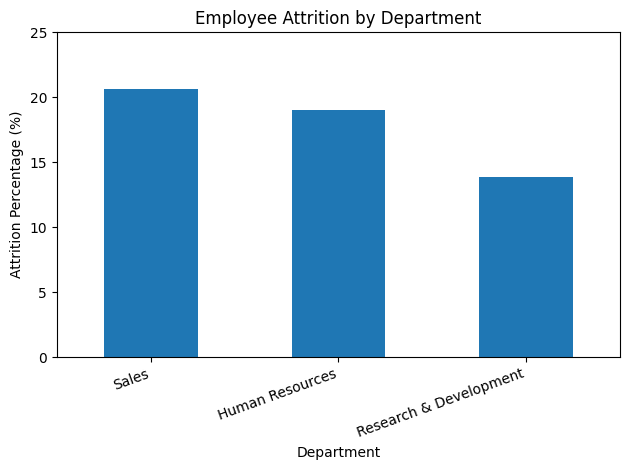


ATTRITION BY OVERTIME
OverTime
No     10.44
Yes    30.53
Name: LeftCompany, dtype: float64


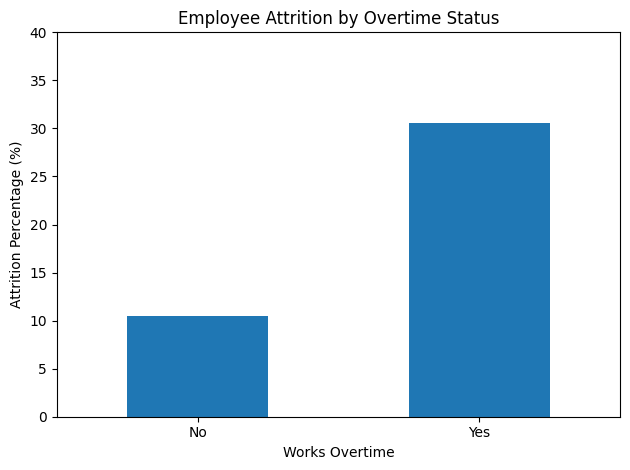


ATTRITION BY JOB SATISFACTION
JobSatisfaction
1    22.84
2    16.43
3    16.52
4    11.33
Name: LeftCompany, dtype: float64


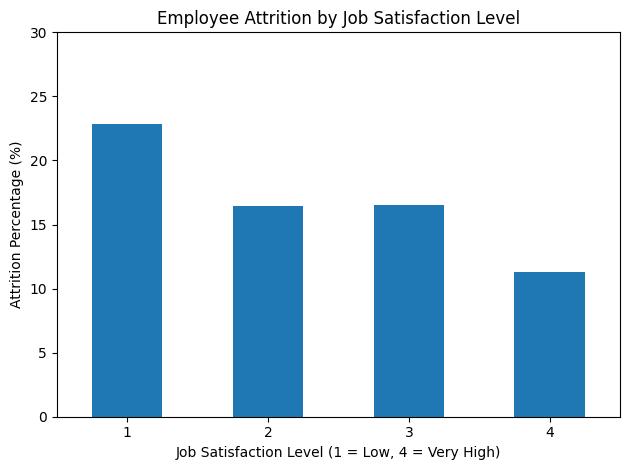

In [26]:

# WORKFORCE ATTRITION ANALYSIS
# IBM HR Analytics Dataset


#IMPORT LIBRARIES

import pandas as pd
import matplotlib.pyplot as plt


# LOAD AND EXPLORE THE DATASET
# Read the CSV file into a pandas DataFrame.

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

# Preview the first five employee records.
print(df.head())

# Display the number of rows and columns.
print("\nDataset shape:", df.shape)


# CHECK DATA QUALITY
# Check for missing values in each column.

print("\nMissing values:")
print(df.isnull().sum())

# Count exact duplicate rows.
print("\nDuplicate rows:", df.duplicated().sum())


# CALCULATE OVERALL ATTRITION
# Count employees whose Attrition value is "Yes".

employees_left = (df["Attrition"] == "Yes").sum()

# Count the total number of employee records.
total_employees = len(df)

# Calculate the percentage of employees who left.
attrition_percentage = (employees_left / total_employees) * 100

print("\nOVERALL ATTRITION")
print("Total employees:", total_employees)
print("Employees who left:", employees_left)
print(f"Attrition percentage: {attrition_percentage:.2f}%")


# CREATE A BOOLEAN COLUMN FOR ATTRITION
# True = employee left; False = employee stayed.
# This makes calculating group percentages easier.

df["LeftCompany"] = df["Attrition"] == "Yes"


#  ANALYZE ATTRITION BY DEPARTMENT
# Calculate attrition percentages for each department.

department_rates = (
    df.groupby("Department")["LeftCompany"].mean() * 100
)

# Sort from highest to lowest percentage.
department_rates = department_rates.sort_values(ascending=False)

print("\nATTRITION BY DEPARTMENT")
print(department_rates.round(2))


# CREATE A DEPARTMENT SUMMARY TABLE
# Calculate employee counts, departures, and attrition rates.

department_summary = df.groupby("Department").agg(
    TotalEmployees=("LeftCompany", "size"),
    EmployeesLeft=("LeftCompany", "sum"),
    AttritionRate=("LeftCompany", "mean")
)

# Convert the attrition rate to a percentage.
department_summary["AttritionRate"] *= 100

# Sort departments by attrition percentage.
department_summary = department_summary.sort_values(
    "AttritionRate", ascending=False
)

print("\nDEPARTMENT SUMMARY")
print(department_summary.round(2))


# VISUALIZE ATTRITION BY DEPARTMENT
# Create a bar chart to compare department percentages.

department_rates.plot(kind="bar")

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Percentage (%)")

# Rotate long department names for readability.
plt.xticks(rotation=20, ha="right")

# Start the percentage axis at zero.
plt.ylim(0, 25)

plt.tight_layout()
plt.show()


# ANALYZE ATTRITION BY OVERTIME
# Compare employees who work overtime with those who do not.

overtime_rates = (
    df.groupby("OverTime")["LeftCompany"].mean() * 100
)

print("\nATTRITION BY OVERTIME")
print(overtime_rates.round(2))


# VISUALIZE ATTRITION BY OVERTIME
# Create a bar chart for overtime status.

overtime_rates.plot(kind="bar")

plt.title("Employee Attrition by Overtime Status")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Percentage (%)")

# Keep category labels horizontal.
plt.xticks(rotation=0)

plt.ylim(0, 40)

plt.tight_layout()
plt.show()


#  ANALYZE ATTRITION BY JOB SATISFACTION
# Satisfaction is recorded on a scale from 1 to 4.

satisfaction_rates = (
    df.groupby("JobSatisfaction")["LeftCompany"].mean() * 100
)

print("\nATTRITION BY JOB SATISFACTION")
print(satisfaction_rates.round(2))


#  VISUALIZE ATTRITION BY JOB SATISFACTION
# Compare attrition across satisfaction levels.

satisfaction_rates.plot(kind="bar")

plt.title("Employee Attrition by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level (1 = Low, 4 = Very High)")
plt.ylabel("Attrition Percentage (%)")

plt.xticks(rotation=0)
plt.ylim(0, 30)

plt.tight_layout()
plt.show()


# Key Findings

1. Overall Employee Attrition

  Out of 1,470 employee records, 237 employees were marked as having left the company, representing approximately 16.12% of the dataset.

2. Department Differences

  Sales had the highest attrition percentage at approximately 20.63%, followed by Human Resources at 19.05% and Research & Development at 13.84%. This suggests that attrition patterns differ across departments.

3. Overtime and Attrition

  Employees who worked overtime had an attrition percentage of approximately 30.53%, compared with 10.44% for employees who did not work overtime. This was one of the largest differences observed in the analysis.

4. Job Satisfaction and Attrition

  Employees reporting the lowest job satisfaction had an attrition percentage of approximately 22.84%, compared with 11.33% among those reporting the highest satisfaction.

These results identify associations in a synthetic HR dataset. They do not establish that overtime, department, or job satisfaction caused employees to leave.

# Recommendations

Based on the findings, I would recommend that an HR team:


1.   Investigate overtime and workload: Examine whether employees working overtime experience greater workload pressure, and review employee feedback to better understand the relationship with attrition.



2.   Explore department-specific trends: Look more closely at Sales to understand whether factors such as job responsibilities, compensation, or management practices may be associated with higher attrition.


3.   Monitor employee satisfaction: Use employee surveys and feedback to identify concerns and evaluate whether satisfaction levels change over time.

**Limitations**

This analysis uses a synthetic dataset rather than real company records. The results are descriptive and cannot establish cause-and-effect relationships. Additional data and analysis would be necessary before making workforce policy decisions.